# 00 · Email Parsing

**Goal:** give email entries the same fields as every other entry (CMID, client, matter, hours, narrative) before matching starts.

Typed sheets, PDFs, and handwritten sheets have their own CMID, client, and matter fields. Emails don't. Everything is in the body, mixed in with greetings, sign-offs, and phone footers. A firm would pull those fields out during extraction, so matching should see emails the same way.

**Approach:** rules only, with no model and nothing learned from labeled entries. The rules come from common email and billing conventions plus the firm's own client list.

| Step | What it handles | Example |
|---|---|---|
| Strip clutter | reply chains, quoted lines, signatures, phone footers, notices, greetings | "On Oct 14 ... wrote:", "Sent from my iPhone" |
| Strip requests | notes to the person entering time | "Please enter the following for today:" |
| Hours | decimals, minutes, hours and minutes, clock style | ".4", "1.5 hrs", "45 min", "1:15" |
| CMID | client-matter numbers with any separator | "7215.003", "C/M 7215/003" |
| Client | names, aliases, and initials from the client list, allowing typos | "HalvorsenIndustrial", "JPC" |
| Matter | "Client / Matter" pairs, labeled fields, codename headers | "Cobalt Ridge Partners / Fund II" |
| Fallback | a short name-like header, for clients not on the list yet | "Quarry Lane Ventures - kickoff call" |

**Output:** `results/00_entries.parquet`, every entry with the email rows parsed. Notebook 02 reads it instead of the raw entries.

**Questions**
1. What do email entries look like next to the other formats?
2. Does the parser handle common email layouts it wasn't built around?
3. How often does it recover the right hours, client, and CMID?
4. What does it miss?

## 1. Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from clean import clean_cmid, is_blank
from fuzzy import client_name_table, matter_name_table, match
from email_parser import parse_email, parse_email_entries, client_lookup, matter_lookup

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
SHORTHAND_PATH = Path("../data/shorthand_bank.csv")   # billing shorthand, never read as client initials
RESULTS_DIR = Path("../results")

ENTRY_COLS = {"Time ID": "entry_id", "TK ID": "tk_id", "Source Format": "source_format", "Date": "work_date",
              "CMID": "cmid", "Client": "client", "Matter": "matter", "Narrative": "narrative", "Hours": "hours"}
SKIP_CLIENTS = ["Firm"]   # an ordinary word, so "firm meeting" doesn't name a client
CLIENT_MIN = 80           # typed client score that counts as pointing to a client (same scale as notebook 01)

## 2. Load data

The answer key (`KEY:` columns) is only used to grade the parser at the end. The parser itself only sees the entry and the firm's client and matter lists.

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None, dtype=str)
raw, matter_master = sheets["Time Entries"], sheets["Matter Master"]

entries = raw[list(ENTRY_COLS)].rename(columns=ENTRY_COLS)
answers = raw[["Time ID", "KEY: Split", "KEY: True CMID", "KEY: True Client", "KEY: Entry Category"]]
answers.columns = ["entry_id", "split", "true_cmid", "true_client", "category"]
acronym_skip = pd.read_csv(SHORTHAND_PATH)["shorthand"].tolist()
client_names = client_name_table(matter_master, acronym_skip)
matter_names = matter_name_table(matter_master)

assert entries["entry_id"].is_unique
assert not any(c.startswith("KEY") for c in entries.columns)
print(f"{len(entries):,} entries | {(entries['source_format'] == 'EMAIL').sum()} emails | {len(client_names)} client names, aliases, and initials")

4,000 entries | 389 emails | 83 client names, aliases, and initials


## 3. What emails look like

In [4]:
filled = entries[["cmid", "client", "matter"]].notna().groupby(entries["source_format"]).mean()
filled.round(2)

,cmid,client,matter
source_format,,,
EMAIL,0.00,0.00,0.00
HANDWRITTEN,0.54,0.74,0.31
PDF,0.53,0.75,0.33
TYPED,0.55,0.75,0.31


In [5]:
emails = entries[entries["source_format"] == "EMAIL"]
emails["narrative"].sample(8, random_state=0).to_frame()

,narrative
633,0:24 Halverson Industries-gen exchange emails ...
1301,1.2 CRP prepare first dft of drawdown notice r...
2792,[MeridianTherapeutics] Make edits to governanc...
1753,0.6 Maridian Therapeutics Follow up with clien...
2980,Lantern Software Group: Revw funds flow for Vi...
2318,.3 Lnaternfish Software / Exec Comp / 409AA Fo...
3208,1.1 Lumen Oak Health Attend closing call. -SK
2975,Solaca Health: provide cmts on foreign qualifi...


- **Emails come in with nothing in the CMID, client, or matter fields.** The other formats have each field filled about a third to three quarters of the time.
- The client, matter, and hours are usually right there in the body, next to requests ("Pls enter"), sign-offs ("thx, LM"), and footers.
- Without parsing, matching would treat every email like an entry nobody filled in.

## 4. Check on common email layouts

Before the synthetic emails, the parser is checked on 10 emails written to look like what a legal assistant actually gets: Outlook replies with the old thread below, phone replies, a list of entries, a labeled form, a confidentiality notice, a forward, and minutes or clock-style hours. None of these layouts are in the synthetic data. They use the synthetic firm's clients, since the parser looks names up in the firm's list.

Each email and what a person would pull out of it are in the next cell.

In [6]:
# Emails in common layouts, and what a person would pull out of each one
examples = [
    {
        "layout": "Outlook reply",
        "text": """Hi Pat,

Please enter the following for today:
Harborlight Bio / General Corporate - reviewed board consent for option grants, 0.6 hrs

Thanks,
Alex

Alex Chen | Associate
Corporate Group

From: Pat Lee
Sent: Monday, October 12, 2026 9:02 AM
To: Alex Chen
Subject: Time for last week?

Hi Alex, can you send me your time from last week?""",
        "expected": [{"client": "Harborlight Bio", "hours": 0.6, "cmid": None}],
    },
    {
        "layout": "Phone reply",
        "text": """1.5 on Meridian Therapeutics annual meeting - revised proxy draft and sent to client

Sent from my iPhone

On Oct 14, 2026, at 6:02 PM, Pat Lee <plee@example.com> wrote:
> Reminder to send your time today""",
        "expected": [{"client": "Meridian Therapeutics", "hours": 1.5, "cmid": None}],
    },
    {
        "layout": "List of entries",
        "text": """My time for 10/13:
- Juniper Peak Capital (9140.001): call with GP re LPA comments .4
- Cobalt Ridge Partners / Fund II: revise subscription docs 1.2
- Pelican Row Holdings: review title commitment 1 hr

Thx
M""",
        "expected": [{"client": "Juniper Peak Capital", "hours": 0.4, "cmid": "9140.001"},
                     {"client": "Cobalt Ridge Partners", "hours": 1.2, "cmid": None},
                     {"client": "Pelican Row Holdings", "hours": 1.0, "cmid": None}],
    },
    {
        "layout": "Labeled fields",
        "text": """Client: Lanternfish Software
Matter: Series C Financing
Time: 2 hours 15 minutes
Description: Drafted disclosure schedules and circulated to company counsel.""",
        "expected": [{"client": "Lanternfish Software", "hours": 2.25, "cmid": None}],
    },
    {
        "layout": "Confidentiality notice",
        "text": """Pelican Row Holdings - 45 min - call w/ title co re survey exceptions

Jordan

CONFIDENTIALITY NOTICE: This e-mail message and any attachments are privileged and confidential and intended only for the named recipient.""",
        "expected": [{"client": "Pelican Row Holdings", "hours": 0.75, "cmid": None}],
    },
    {
        "layout": "Minutes and CMID",
        "text": """Please bill 30 min to 7215-003 for reviewing the Asterion amendment redline. Thanks!""",
        "expected": [{"client": None, "hours": 0.5, "cmid": "7215.003"}],
    },
    {
        "layout": "Client not on the list",
        "text": """Pls log 0.8 hrs for Quarry Lane Ventures - kickoff call re new engagement
-JD""",
        "expected": [{"client": "Quarry Lane Ventures", "hours": 0.8, "cmid": None}],
    },
    {
        "layout": "Alias and clock hours",
        "text": """JPC fund II - 1:15 - markup of side letter
Best,
T""",
        "expected": [{"client": "JPC", "hours": 1.25, "cmid": None}],
    },
    {
        "layout": "Rule and Item numbers",
        "text": """Meridian Therapeutics: researched Rule 10b5-1 plan requirements and Item 5.02 disclosure, 2.3h""",
        "expected": [{"client": "Meridian Therapeutics", "hours": 2.3, "cmid": None}],
    },
    {
        "layout": "Forward",
        "text": """---------- Forwarded message ---------
From: Dana Park <dpark@example.com>
Date: Tue, Oct 13, 2026 at 5:40 PM
Subject: time
To: Billing <billing@example.com>

Northgate Bank / Asterion: conference call with lender counsel re amendment 2.0""",
        "expected": [{"client": "Northgate Bank", "hours": 2.0, "cmid": None}],
    },
]

In [7]:
print(examples[0]["text"])

Hi Pat,

Please enter the following for today:
Harborlight Bio / General Corporate - reviewed board consent for option grants, 0.6 hrs

Thanks,
Alex

Alex Chen | Associate
Corporate Group

From: Pat Lee
Sent: Monday, October 12, 2026 9:02 AM
To: Alex Chen
Subject: Time for last week?

Hi Alex, can you send me your time from last week?


In [8]:
lookup = client_lookup(client_names, SKIP_CLIENTS)
matters = matter_lookup(matter_names)

rows = []
for ex in examples:
    found = parse_email(ex["text"], lookup, matters)
    got = [{"client": f["client"], "hours": f["hours"], "cmid": f["cmid"]} for f in found]
    for f in found:
        rows.append({"layout": ex["layout"], **f, "as_expected": got == ex["expected"]})
general = pd.DataFrame(rows)
print(f"{general.drop_duplicates('layout')['as_expected'].sum()} of {len(examples)} emails parsed as expected")
general

10 of 10 emails parsed as expected


,layout,cmid,client,matter,hours,narrative,as_expected
0,Outlook reply,NaN,Harborlight Bio,General Corporate,0.60,reviewed board consent for option grants,True
1,Phone reply,NaN,Meridian Therapeutics,NaN,1.50,annual meeting - revised proxy draft and sent ...,True
2,List of entries,9140.001,Juniper Peak Capital,NaN,0.40,call with GP re LPA comments,True
3,List of entries,NaN,Cobalt Ridge Partners,Fund II,1.20,revise subscription docs,True
4,List of entries,NaN,Pelican Row Holdings,NaN,1.00,review title commitment,True
5,Labeled fields,NaN,Lanternfish Software,Series C Financing,2.25,Drafted disclosure schedules and circulated to...,True
6,Confidentiality notice,NaN,Pelican Row Holdings,NaN,0.75,call w/ title co re survey exceptions,True
7,Minutes and CMID,7215.003,NaN,NaN,0.50,reviewing the Asterion amendment redline.,True
8,Client not on the list,NaN,Quarry Lane Ventures,NaN,0.80,kickoff call re new engagement,True
9,Alias and clock hours,NaN,JPC,NaN,1.25,fund II - markup of side letter,True


- **All 10 come out as expected,** including the ones with reply chains, signatures, and a notice below the entry.
- **A list of entries becomes one entry per line,** each with its own client and hours.
- **References aren't read as hours.** "Rule 10b5-1" and "Item 5.02" are skipped, since a word like "Rule" or "Item" right before a number marks it as a reference.
- **A client that isn't on the list still fills the client field** ("Quarry Lane Ventures"). Matching then sees a name that fits no client, which is a hint for `NO_MATCH`.

## 5. Run on the synthetic emails

In [9]:
parsed = parse_email_entries(entries, client_names, matter_names, skip=SKIP_CLIENTS)
is_email = parsed["source_format"] == "EMAIL"

assert parsed.index.equals(entries.index)
assert parsed.loc[~is_email, ["cmid", "client", "matter", "narrative"]].equals(entries.loc[~is_email, ["cmid", "client", "matter", "narrative"]])
print("Entries found per email:", parsed.loc[is_email, "n_parsed"].value_counts().to_dict())

before_after = entries.loc[is_email, ["narrative"]].merge(parsed.loc[is_email, ["cmid", "client", "matter", "parsed_hours", "narrative"]],
                                                         left_index=True, right_index=True, suffixes=("", "_parsed"))
before_after.sample(8, random_state=1)

Entries found per email: {1: 389}


,narrative,cmid,client,matter,parsed_hours,narrative_parsed
1025,1.8h Pelican Row Holdings Attend to drafting o...,NaN,Pelican Row Holdings,NaN,1.8,Attend to drafting of zoning letter
1802,[Cobalt] update capital account statements -- ...,NaN,Cobalt,NaN,2.8,update capital account statements
1315,[Harborlight Bio / gen corp] Handle annual fil...,NaN,Harborlight Bio,gen corp,0.3,Handle annual filings and follow up on open it...
677,Firm / firm admin: Complete conflicts training...,NaN,Firm,firm admin,0.7,Complete conflicts training.
2450,[Ridgewater] attend to LP matters. -- 2.0 hrs -EB,NaN,Ridgewater,NaN,2.0,attend to LP matters.
3510,Pls enter 2.2 for Meridian Tx - Exchange email...,NaN,Meridian Tx,NaN,2.2,Exchange emails with R. Iyer re say-on-pay; lo...
2617,Pls enter 1:18 for Meridian Tx - Read through ...,NaN,Meridian Tx,NaN,1.3,Read through governance guidelines.
3216,Ridgawater Partners / Fund IV: attend to fund ...,NaN,Ridgawater Partners,Fund IV,0.9,attend to fund formatiion matters


## 6. How well it parses

Each TRAIN and VAL email is checked against the answer key. TEST is left for the final run.

| Check | Question |
|---|---|
| Hours | Do the parsed hours match the `Hours` column? |
| Client | Does the parsed client point to the true client (notebook 01's fuzzy matching, score 80+)? Or to a *wrong* client, which is worse than leaving it blank? |
| CMID | When one is found, is it the true CMID after cleanup? |
| New clients | For clients not in Matter Master, does the client field still get filled? |

In [10]:
def pointed_client(name):
    top = match(name, client_names, k=1) if not is_blank(name) else []
    return top[0][0] if top and top[0][1] >= CLIENT_MIN else None


check = parsed[is_email].merge(answers.query("split != 'TEST'"), on="entry_id")
check["client_pick"] = check["client"].map(pointed_client)
check["known"] = check["true_cmid"] != "NONE"
check["hours_diff"] = (check["parsed_hours"].astype(float) - check["hours"].astype(float)).abs()

check["hours_match"] = check["hours_diff"] < 0.05
check["hours_close"] = check["hours_diff"] <= 0.15
check["client_filled"] = check["client"].notna()
check["right_client"] = check["client_pick"] == check["true_client"]
check["wrong_client"] = check["client_pick"].notna() & ~check["right_client"]
check["matter_filled"] = check["matter"].notna()

known = check[check["known"]].groupby("split")[["right_client", "wrong_client"]].mean()
new = check[~check["known"]].groupby("split")["client_filled"].mean().rename("new_client_filled")
scores = check.groupby("split")[["hours_match", "hours_close", "client_filled", "matter_filled"]].mean().join(known).join(new)
scores.insert(0, "emails", check.groupby("split").size())
scores = scores.reindex(["TRAIN", "VAL"])
scores.round(3)

,emails,hours_match,hours_close,client_filled,matter_filled,right_client,wrong_client,new_client_filled
split,,,,,,,,
TRAIN,273,0.96,1.0,0.769,0.308,0.735,0.016,0.750
VAL,67,0.94,1.0,0.701,0.224,0.655,0.052,0.444


In [11]:
found = check[check["cmid"].notna()]
print(f"CMIDs found: {len(found)} | right after cleanup: {(found['cmid'].map(clean_cmid) == found['true_cmid']).sum()}")

CMIDs found: 19 | right after cleanup: 6


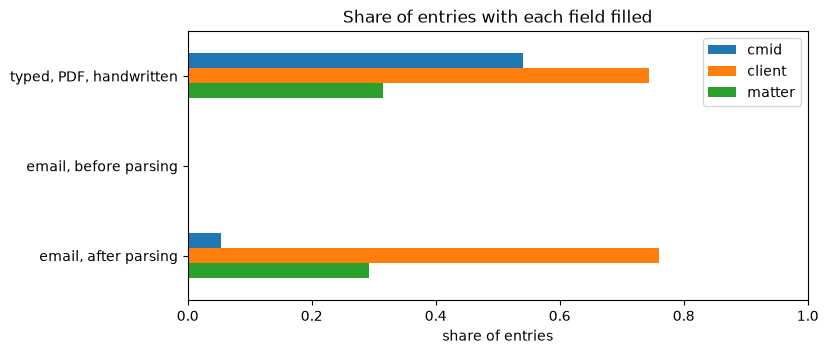

In [12]:
fill = pd.DataFrame({
    "typed, PDF, handwritten": entries.loc[~is_email, ["cmid", "client", "matter"]].notna().mean(),
    "email, before parsing": entries.loc[is_email, ["cmid", "client", "matter"]].notna().mean(),
    "email, after parsing": parsed.loc[is_email, ["cmid", "client", "matter"]].notna().mean(),
})
ax = fill.T.plot.barh(figsize=(8, 3.5), xlim=(0, 1), title="Share of entries with each field filled")
ax.set_xlabel("share of entries")
ax.invert_yaxis()
plt.show()

- **Hours match what's written every time.** About 96% match the `Hours` column exactly, and the rest are within 0.15 hours (the email says ".8" and the column has 0.75). That's rounding in the synthetic data, not a parsing miss.
- **The client field goes from always empty to filled for about three quarters of emails.** It's the right client for about 70% of emails from known clients and a wrong one for 2 to 5%.
- **TRAIN and VAL look alike,** as expected for rules that aren't fit to either. VAL only has about 70 emails, so a few entries move it several points.
- **CMIDs are rare in emails** (about 1 in 20), and only about a third of them are real. The rest are typos ("Zg60.003") or numbers that aren't in Matter Master, which matching already treats as a warning sign.
- **Most new-client emails get a client name,** which gives matching a name that fits nothing.

## 7. What it misses

In [13]:
missed = check[check["known"] & (check["client_pick"] != check["true_client"])]
missed["category"].value_counts().rename("emails without the right client").to_frame()

,emails without the right client
category,
MESSY,28
INCOMPLETE,26
AMBIGUOUS,22
SPLIT_NAMED,6
SPLIT_UNNAMED,4


In [14]:
missed.merge(raw[["Time ID", "Narrative"]], left_on="entry_id", right_on="Time ID")[["Narrative", "client", "true_client"]].head(12)

,Narrative,client,true_client
0,"time for today: HB, Edit good standing certifi...",NaN,Harborlight Bio
1,Pls enter 2:36: mark up inv. register; circula...,NaN,Cobalt Ridge Partners
2,"time for today: 5524-002, exchange emails w/ W...",NaN,Cobalt Ridge Partners
3,Attend to annual filings; plus time on other d...,NaN,Bluefin Robotics
4,Attend practice group mtg (0.4),NaN,Firm
5,time for today: Cobalt Rock Partners / fund ge...,Cobalt Rock,Cobalt Ridge Partners
6,Pls enter 0.4: Attend to property acquisition.,NaN,Pelican Row Holdings
7,[Project Atlas] attend to rvw of escrow agt in...,NaN,Northgate Capital Partners
8,"Pls enter 0.4h: T/c w/ M. Carter. thx, FC",NaN,Pelican Row Holdings
9,42 min Firm interview summer associate candidates,NaN,Firm


- **About 8 in 10 misses have no client in the email at all** ("Pls enter 0.4: Attend to property acquisition."). There's nothing to parse, so matching leans on the narrative and the timekeeper's history, like any incomplete entry.
- **Short or shared initials aren't recognized** ("HB", "PL"). Initials are only built when they're three or more letters and belong to one client ("CRP"). The rest need the firm's alias list.
- **Lookalike names are read as the closest real name.** "Cobalt Rock Partners" becomes "Cobalt Rock", an alias of Cobalt Rock Capital. That's the right reading of what was written, and matching decides from there.
- **Cut-off names stay in the narrative** ("Aster &", "Pelican Row Ho"), since they fall below the match score.

## 8. Save

- `00_entries.parquet`: every entry in the raw file's order, with email rows parsed into `cmid`, `client`, `matter`, and `narrative`. `parsed_hours` and `n_parsed` are kept for reference, and other formats are unchanged.

In [15]:
out = parsed.drop(columns=["hours"])
out.to_parquet(RESULTS_DIR / "00_entries.parquet", index=False)
print(f"Saved 00_entries.parquet: {len(out):,} entries, {is_email.sum()} parsed emails")

Saved 00_entries.parquet: 4,000 entries, 389 parsed emails


## 9. Findings

### Results
- **Emails were the only format with empty fields,** even though most name the client in the body. That made them look harder to matching than they are.
- **The parser fills the client field for about three quarters of emails,** hours match what's written, and wrong clients are rare (2 to 5%).
- **It handles layouts it wasn't built around:** reply chains, forwards, signatures, notices, lists, and labeled forms.

### Why rules
- **Rules only use what a firm has:** the email and the client and matter lists. No answer key and no learned weights, so nothing has to be retrained when the data changes.
- **The tradeoff:** a rule can't recover what isn't written. Emails that never name the client are left for matching, which uses the narrative and the timekeeper's history.

### Limitations
- The synthetic emails reuse a fixed set of phrasings, so section 6 is likely higher than real emails would score. Section 4 is a better sense of new layouts, but those emails are still made up.
- Nicknames and short or shared initials only work once they're on the firm's alias list.
- An email with several entries keeps the first entry's fields and joins the narratives, like a block-billed entry. In the app, each entry would be its own row.
- Only plain text is handled. HTML emails need to be converted first, which most email exports already do.

### Next steps
- `01_fuzzy_scorer_comparison`: pick the fuzzy scorers for typed client and matter names.
- `02_feature_building`: build the matching clues from `00_entries.parquet`, so emails reach matching with their fields filled in.